In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, classification_report)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Libraries loaded")

Libraries loaded


In [2]:
import os, zipfile
from google.colab import files

COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
        "exang", "oldpeak", "slope", "ca", "thal", "num"]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

up = files.upload()
path = None
for name in up:
    if name.lower().endswith(".zip"):
        with zipfile.ZipFile(name) as z:
            z.extractall("heartdisease")
        path = os.path.join("heartdisease", "processed.cleveland.data")
    elif "cleveland" in name.lower():
        path = name

if path and os.path.exists(path):
    df_raw = pd.read_csv(path, header=None, names=COLS, na_values="?")
    print("Loaded from your file:", path)
else:
    df_raw = pd.read_csv(URL, header=None, names=COLS, na_values="?")
    print("Loaded from the official UCI link")
print(df_raw.shape)

Saving heart+disease.zip to heart+disease.zip
Loaded from your file: heartdisease/processed.cleveland.data
(303, 14)


In [3]:
display(df_raw.head())
print("Shape:", df_raw.shape)
print("\nMissing values per column:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
print("\nDuplicate rows:", df_raw.duplicated().sum())
display(df_raw.describe().T)
print("\nOriginal target values (num):")
print(df_raw["num"].value_counts().sort_index())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Shape: (303, 14)

Missing values per column:
ca      4
thal    2
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



Original target values (num):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [4]:
df = df_raw.drop_duplicates().copy()
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

# make sure every column is numeric
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Rows:", len(df))
print("Class balance (0 = no disease, 1 = disease):")
print(df["target"].value_counts())
print("\nMissing values:", df.isna().sum()[df.isna().sum() > 0].to_dict())

Rows: 303
Class balance (0 = no disease, 1 = disease):
target
0    164
1    139
Name: count, dtype: int64

Missing values: {'ca': 4, 'thal': 2}


In [5]:
NUM = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
CAT = ["cp", "restecg", "slope", "thal"]
BIN = ["sex", "fbs", "exang"]
FEATURES = NUM + CAT + BIN
X, y = df[FEATURES], df["target"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
    ])

def make_pipe(clf):
    return Pipeline([("prep", make_preprocessor()), ("clf", clf)])

print("Features:", len(FEATURES), "| samples:", len(X))

Features: 13 | samples: 303


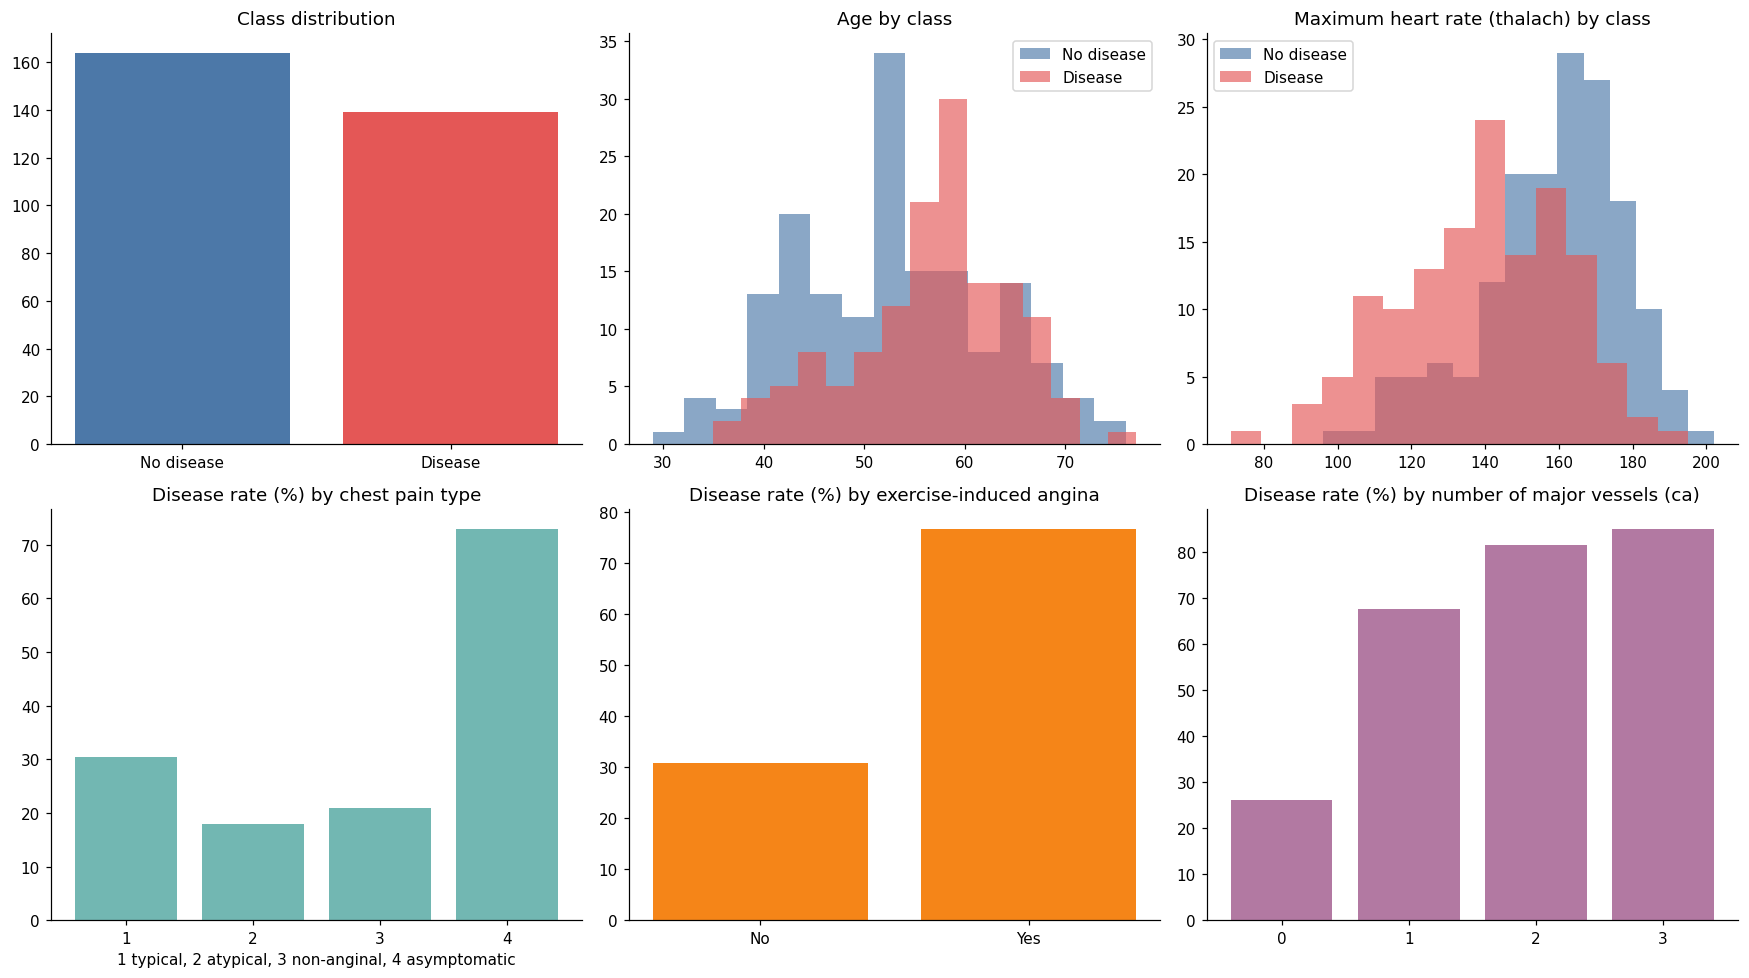

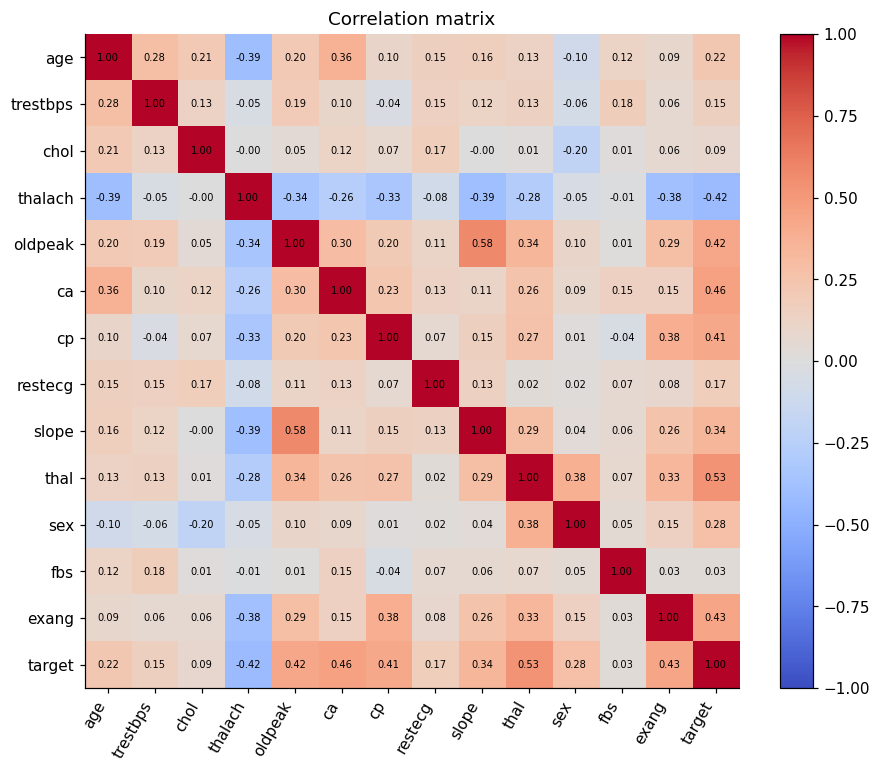

Correlation with the target:
thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64


In [6]:
labels = {0: "No disease", 1: "Disease"}
fig, ax = plt.subplots(2, 3, figsize=(16, 9))

ax[0, 0].bar([labels[i] for i in [0, 1]], y.value_counts().sort_index().values, color=["#4c78a8", "#e45756"])
ax[0, 0].set_title("Class distribution")

for c, col in [(0, "#4c78a8"), (1, "#e45756")]:
    ax[0, 1].hist(df[df.target == c].age, bins=15, alpha=.65, color=col, label=labels[c])
ax[0, 1].set_title("Age by class"); ax[0, 1].legend()

for c, col in [(0, "#4c78a8"), (1, "#e45756")]:
    ax[0, 2].hist(df[df.target == c].thalach, bins=15, alpha=.65, color=col, label=labels[c])
ax[0, 2].set_title("Maximum heart rate (thalach) by class"); ax[0, 2].legend()

rate = df.groupby("cp")["target"].mean() * 100
ax[1, 0].bar(rate.index.astype(int).astype(str), rate.values, color="#72b7b2")
ax[1, 0].set_title("Disease rate (%) by chest pain type"); ax[1, 0].set_xlabel("1 typical, 2 atypical, 3 non-anginal, 4 asymptomatic")

rate = df.groupby("exang")["target"].mean() * 100
ax[1, 1].bar(["No", "Yes"], rate.values, color="#f58518")
ax[1, 1].set_title("Disease rate (%) by exercise-induced angina")

rate = df.groupby("ca")["target"].mean() * 100
ax[1, 2].bar(rate.index.astype(int).astype(str), rate.values, color="#b279a2")
ax[1, 2].set_title("Disease rate (%) by number of major vessels (ca)")
plt.tight_layout(); plt.show()

corr = df[FEATURES + ["target"]].corr()
plt.figure(figsize=(8.5, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

print("Correlation with the target:")
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(3))

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", Xtr.shape, " Test:", Xte.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

Train: (242, 13)  Test: (61, 13)


In [8]:
dt_search = GridSearchCV(
    make_pipe(DecisionTreeClassifier(random_state=SEED)),
    {"clf__max_depth": [2, 3, 4, 5, 6], "clf__min_samples_leaf": [2, 5, 10, 15]},
    cv=cv, scoring="accuracy", n_jobs=-1).fit(Xtr, ytr)
print("Best Decision Tree:", dt_search.best_params_, "CV acc =", round(dt_search.best_score_, 4))

knn_search = GridSearchCV(
    make_pipe(KNeighborsClassifier()),
    {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "clf__weights": ["uniform", "distance"]},
    cv=cv, scoring="accuracy", n_jobs=-1).fit(Xtr, ytr)
print("Best KNN:", knn_search.best_params_, "CV acc =", round(knn_search.best_score_, 4))

Best Decision Tree: {'clf__max_depth': 3, 'clf__min_samples_leaf': 10} CV acc = 0.7849
Best KNN: {'clf__n_neighbors': 5, 'clf__weights': 'uniform'} CV acc = 0.8387


In [10]:
models = {
    "Decision Tree": dt_search.best_estimator_,
    "Naive Bayes":   make_pipe(GaussianNB()),
    "KNN":           knn_search.best_estimator_,
    "ANN (MLP)":     make_pipe(MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", alpha=0.01,
                                             max_iter=2000, random_state=SEED)),
}
print(list(models))

['Decision Tree', 'Naive Bayes', 'KNN', 'ANN (MLP)']


In [11]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = []
for name, m in models.items():
    r = cross_validate(m, X, y, cv=rcv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name,
                 "Accuracy": f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
                 "Precision": f"{r['test_precision'].mean():.3f} ± {r['test_precision'].std():.3f}",
                 "Recall": f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
                 "F1-Score": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
                 "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                 "_acc": r["test_accuracy"].mean(), "_f1": r["test_f1"].mean(), "_rec": r["test_recall"].mean()})
cv_table = pd.DataFrame(rows).set_index("Model")
display(cv_table.drop(columns=["_acc", "_f1", "_rec"]))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Decision Tree,0.789 ± 0.050,0.793 ± 0.057,0.734 ± 0.079,0.761 ± 0.060,0.836 ± 0.047
Naive Bayes,0.815 ± 0.058,0.843 ± 0.061,0.739 ± 0.129,0.780 ± 0.088,0.882 ± 0.038
KNN,0.826 ± 0.042,0.815 ± 0.065,0.813 ± 0.076,0.811 ± 0.047,0.883 ± 0.042
ANN (MLP),0.785 ± 0.037,0.780 ± 0.061,0.751 ± 0.066,0.762 ± 0.039,0.859 ± 0.030


In [12]:
results, cms, probas, preds = {}, {}, {}, {}
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr, ytr); fit_t = time.time() - t0
    pred = m.predict(Xte); proba = m.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    results[name] = {"Accuracy": accuracy_score(yte, pred), "Precision": precision_score(yte, pred),
                     "Recall": recall_score(yte, pred), "F1-Score": f1_score(yte, pred),
                     "ROC-AUC": roc_auc_score(yte, proba), "Specificity": tn / (tn + fp),
                     "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Train time (s)": fit_t,
                     "Train accuracy": accuracy_score(ytr, m.predict(Xtr))}
    cms[name], probas[name], preds[name] = np.array([[tn, fp], [fn, tp]]), proba, pred

results_df = pd.DataFrame(results).T
display(results_df.round(4))
print("Note: the test set has only", len(yte), "patients, so one extra correct prediction changes accuracy by about 1.6 points.")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Specificity,TN,FP,FN,TP,Train time (s),Train accuracy
Decision Tree,0.8689,0.8571,0.8571,0.8571,0.8712,0.8788,29.0,4.0,4.0,24.0,0.0195,0.8430
Naive Bayes,0.6885,0.6098,0.8929,0.7246,0.8474,0.5152,17.0,16.0,3.0,25.0,0.0224,0.7149
KNN,0.8689,0.8125,0.9286,0.8667,0.9324,0.8182,27.0,6.0,2.0,26.0,0.0136,0.8884
ANN (MLP),0.8197,0.7576,0.8929,0.8197,0.9026,0.7576,25.0,8.0,3.0,25.0,1.5458,0.9917


Note: the test set has only 61 patients, so one extra correct prediction changes accuracy by about 1.6 points.


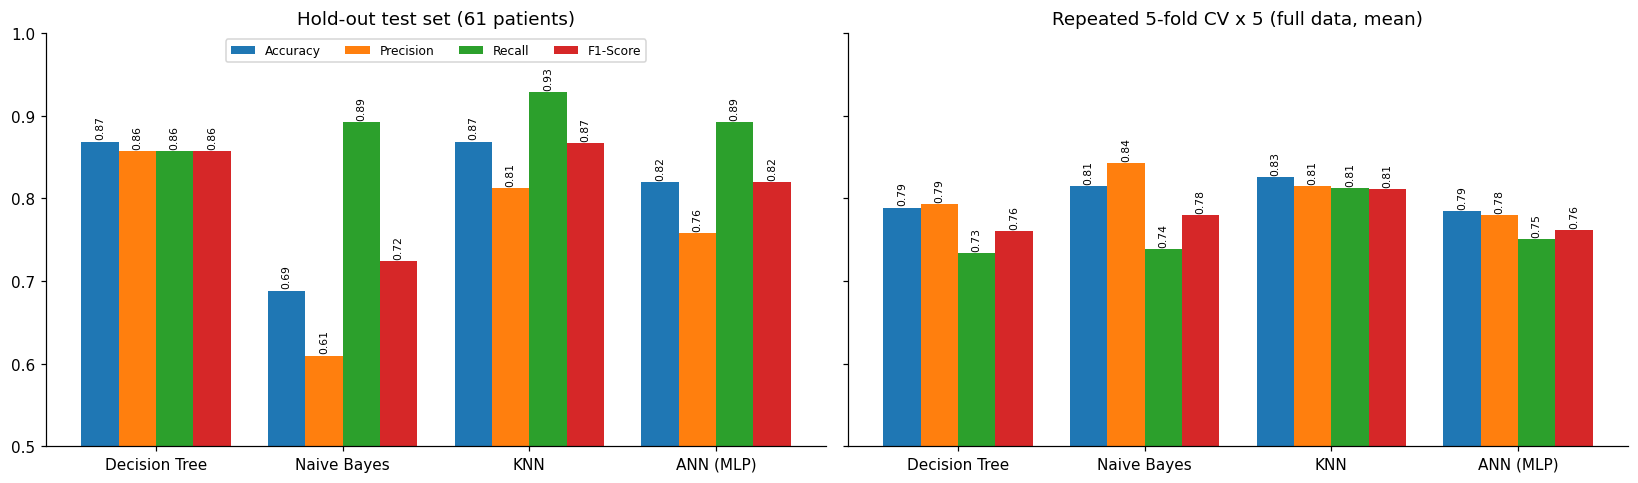

In [13]:
names = list(models)
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)

w = 0.2
for i, mt in enumerate(metrics):
    vals = [results[n][mt] for n in names]
    bars = ax[0].bar(np.arange(4) + i * w, vals, w, label=mt)
    for b, v in zip(bars, vals):
        ax[0].text(b.get_x() + b.get_width() / 2, v + .005, f"{v:.2f}", ha="center", fontsize=7, rotation=90)
ax[0].set_xticks(np.arange(4) + 1.5 * w); ax[0].set_xticklabels(names)
ax[0].set_title("Hold-out test set (61 patients)"); ax[0].set_ylim(.5, 1.0); ax[0].legend(ncol=4, loc="upper center", fontsize=8)

cv_cols = {"Accuracy": "Accuracy", "Precision": "Precision", "Recall": "Recall", "F1-Score": "F1-Score"}
for i, mt in enumerate(metrics):
    vals = [float(cv_table.loc[n, mt].split(" ")[0]) for n in names]
    bars = ax[1].bar(np.arange(4) + i * w, vals, w, label=mt)
    for b, v in zip(bars, vals):
        ax[1].text(b.get_x() + b.get_width() / 2, v + .005, f"{v:.2f}", ha="center", fontsize=7, rotation=90)
ax[1].set_xticks(np.arange(4) + 1.5 * w); ax[1].set_xticklabels(names)
ax[1].set_title("Repeated 5-fold CV x 5 (full data, mean)")
plt.tight_layout(); plt.show()

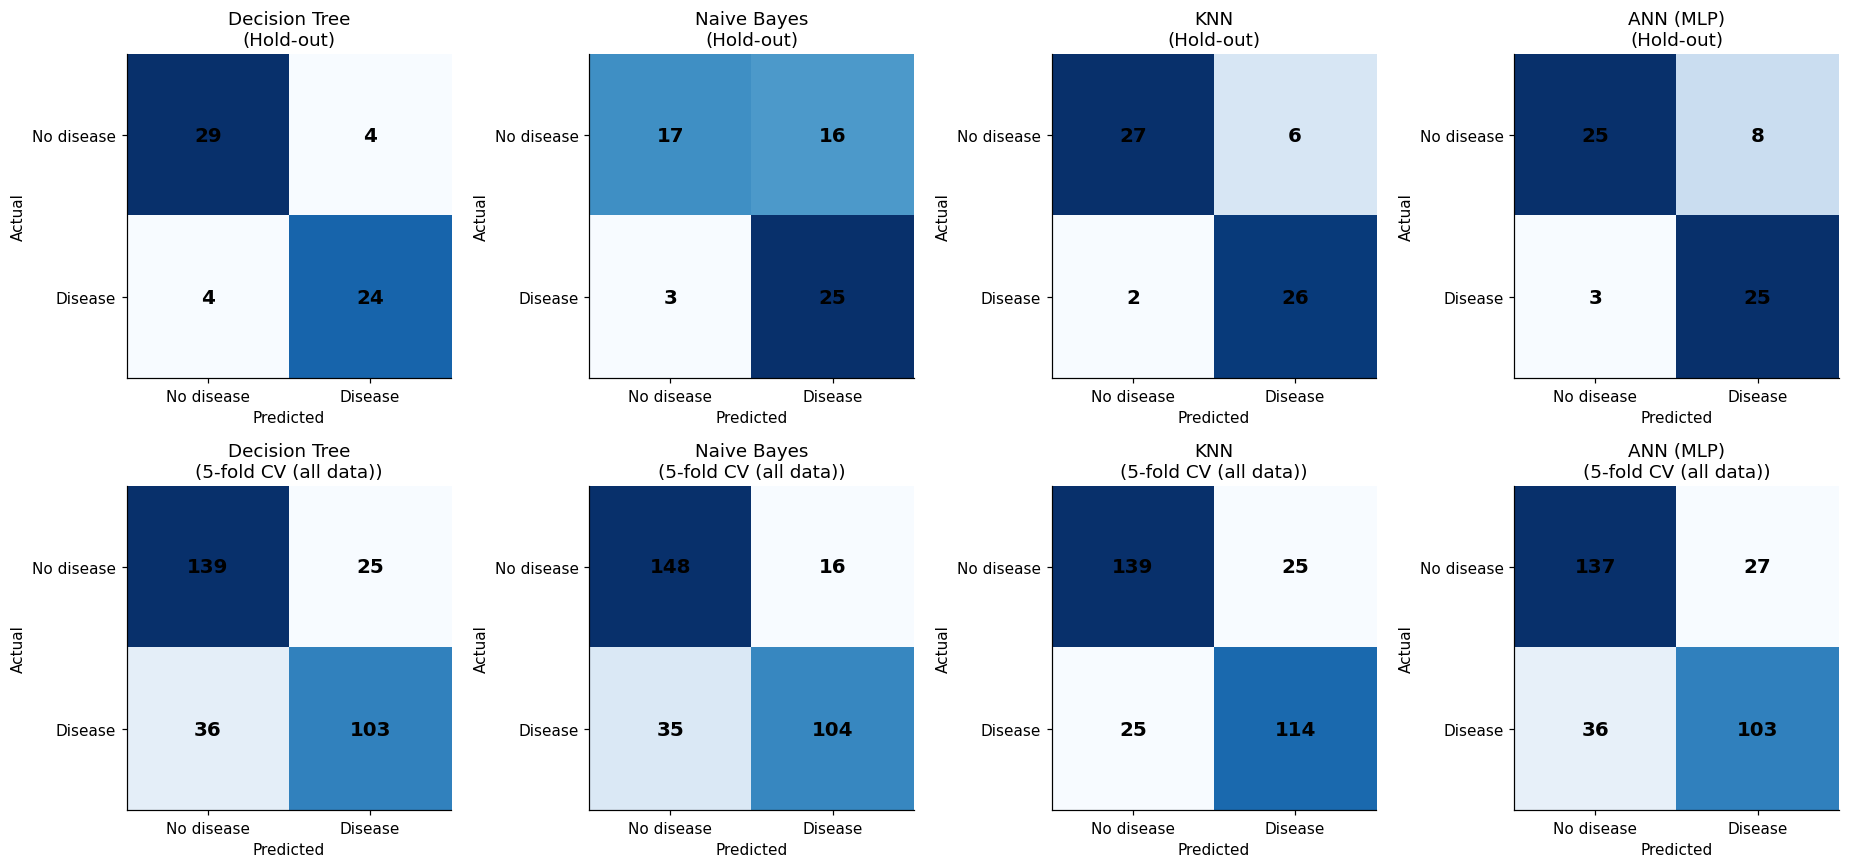

 Decision Tree (hold-out)
              precision    recall  f1-score   support

  No disease      0.879     0.879     0.879        33
     Disease      0.857     0.857     0.857        28

    accuracy                          0.869        61
   macro avg      0.868     0.868     0.868        61
weighted avg      0.869     0.869     0.869        61

 Naive Bayes (hold-out)
              precision    recall  f1-score   support

  No disease      0.850     0.515     0.642        33
     Disease      0.610     0.893     0.725        28

    accuracy                          0.689        61
   macro avg      0.730     0.704     0.683        61
weighted avg      0.740     0.689     0.680        61

 KNN (hold-out)
              precision    recall  f1-score   support

  No disease      0.931     0.818     0.871        33
     Disease      0.812     0.929     0.867        28

    accuracy                          0.869        61
   macro avg      0.872     0.873     0.869        61
weighted

In [14]:
cv_cms = {}
for n in names:
    p = cross_val_predict(models[n], X, y, cv=cv, n_jobs=-1)
    cv_cms[n] = confusion_matrix(y, p)

fig, axs = plt.subplots(2, 4, figsize=(17, 8))
for row, (title, store) in enumerate([("Hold-out", cms), ("5-fold CV (all data)", cv_cms)]):
    for a, n in zip(axs[row], names):
        a.imshow(store[n], cmap="Blues")
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{store[n][i, j]}", ha="center", va="center", fontsize=13, fontweight="bold")
        a.set_xticks([0, 1]); a.set_yticks([0, 1])
        a.set_xticklabels(["No disease", "Disease"]); a.set_yticklabels(["No disease", "Disease"])
        a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.set_title(f"{n}\n({title})")
plt.tight_layout(); plt.show()

for n in names:
    print("=" * 60, "\n", n, "(hold-out)")
    print(classification_report(yte, preds[n], target_names=["No disease", "Disease"], digits=3))

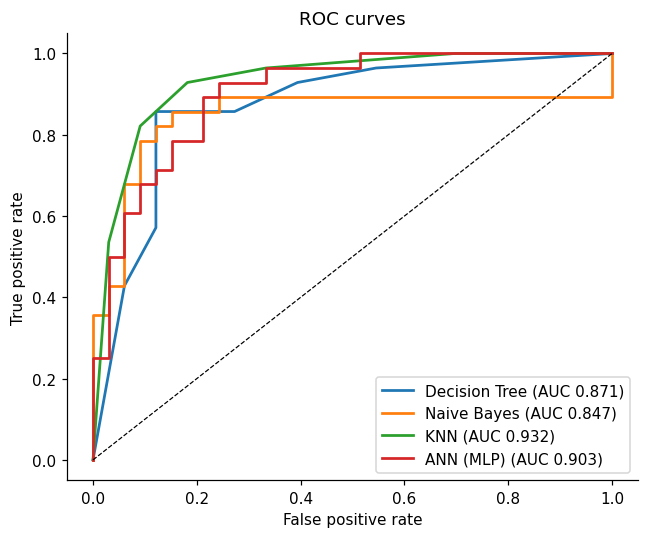

In [15]:
plt.figure(figsize=(6, 5))
for n in names:
    fpr, tpr, _ = roc_curve(yte, probas[n])
    plt.plot(fpr, tpr, lw=1.8, label=f"{n} (AUC {results[n]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend(); plt.tight_layout(); plt.show()

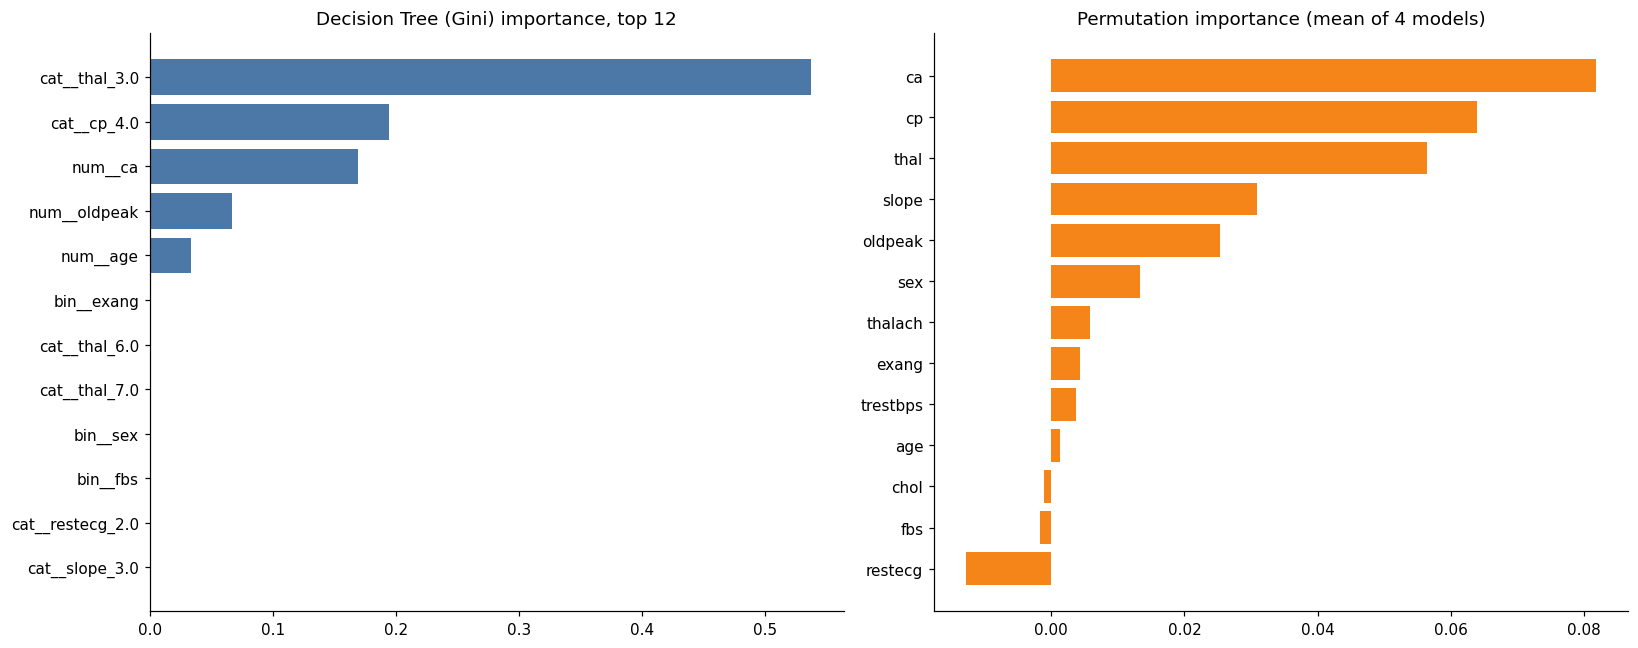

,Decision Tree,Naive Bayes,KNN,ANN (MLP),Mean
ca,0.0989,0.0787,0.0787,0.0710,0.0818
cp,0.1109,0.1115,0.0235,0.0098,0.0639
thal,0.0541,0.1044,0.0350,0.0322,0.0564
slope,0.0000,0.0612,0.0093,0.0530,0.0309
oldpeak,0.0000,0.0683,0.0454,-0.0120,0.0254
sex,0.0000,0.0393,0.0153,-0.0011,0.0134
thalach,0.0000,0.0175,0.0044,0.0016,0.0059
exang,0.0000,0.0344,-0.0033,-0.0137,0.0044
trestbps,0.0000,0.0104,-0.0131,0.0175,0.0037
age,0.0000,0.0060,0.0115,-0.0120,0.0014


In [16]:
dt_pipe = models["Decision Tree"]
enc_names = dt_pipe.named_steps["prep"].get_feature_names_out()
imp_dt = pd.Series(dt_pipe.named_steps["clf"].feature_importances_, index=enc_names).sort_values()

perm = {}
for n in names:
    r = permutation_importance(models[n], Xte, yte, n_repeats=30, random_state=SEED,
                               scoring="accuracy", n_jobs=-1)
    perm[n] = pd.Series(r.importances_mean, index=FEATURES)
perm_df = pd.DataFrame(perm)
perm_mean = perm_df.mean(axis=1).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
imp_top = imp_dt.tail(12)
ax[0].barh(imp_top.index, imp_top.values, color="#4c78a8"); ax[0].set_title("Decision Tree (Gini) importance, top 12")
ax[1].barh(perm_mean.index, perm_mean.values, color="#f58518")
ax[1].set_title("Permutation importance (mean of 4 models)")
plt.tight_layout(); plt.show()

display(perm_df.round(4).assign(Mean=perm_df.mean(axis=1).round(4)).sort_values("Mean", ascending=False))

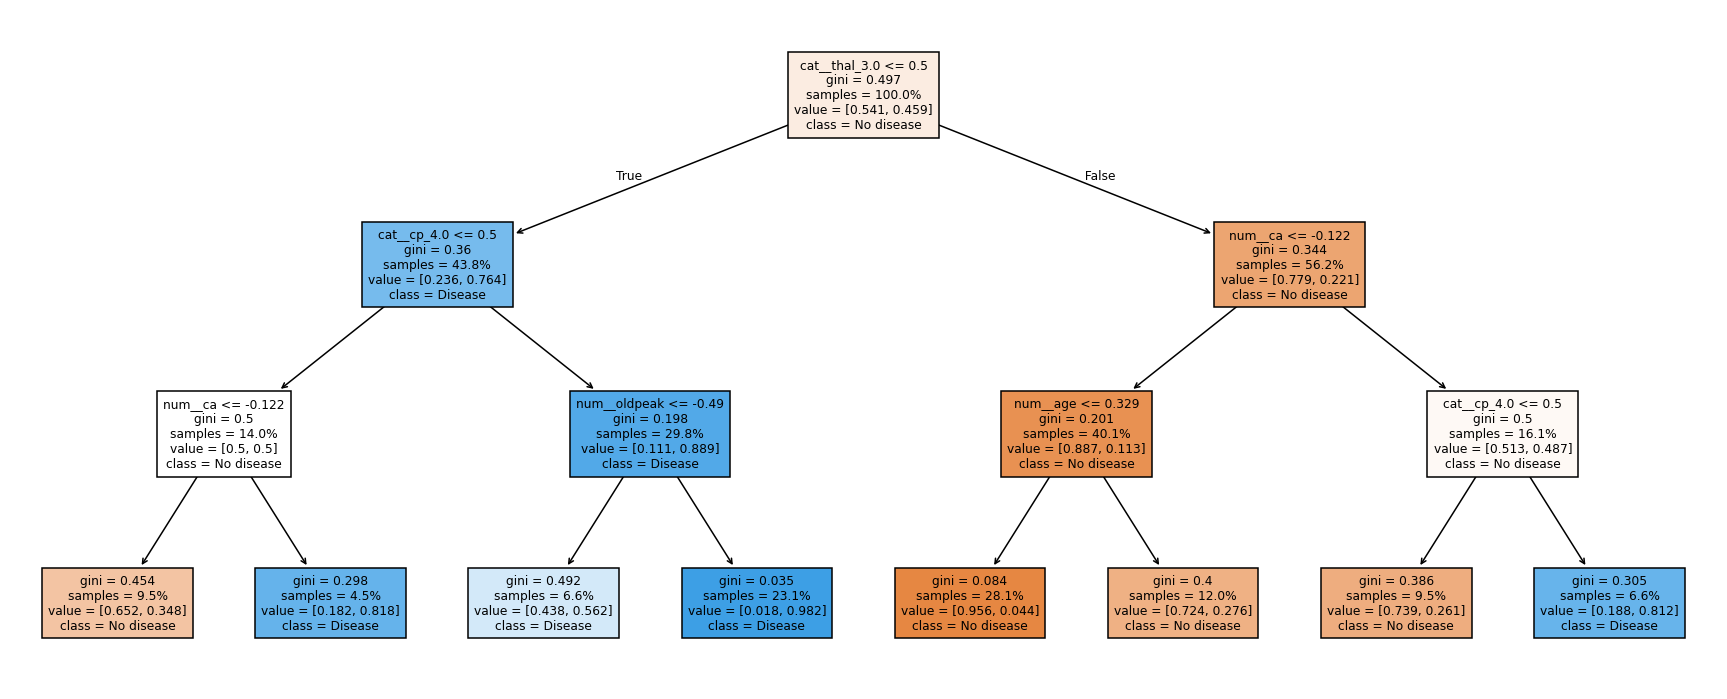

In [17]:
plt.figure(figsize=(20, 8))
plot_tree(dt_pipe.named_steps["clf"], feature_names=list(enc_names), class_names=["No disease", "Disease"],
          filled=True, max_depth=3, fontsize=8, proportion=True)
plt.show()

In [18]:
rank = cv_table[["_f1", "_rec", "_acc"]].sort_values(["_f1", "_rec"], ascending=False)
display(rank.rename(columns={"_f1": "CV F1", "_rec": "CV Recall", "_acc": "CV Accuracy"}).round(4))
best_name = rank.index[0]
print("Best model on repeated cross-validation:", best_name)

,CV F1,CV Recall,CV Accuracy
Model,,,
KNN,0.8106,0.8132,0.8264
Naive Bayes,0.7797,0.7391,0.8150
ANN (MLP),0.7616,0.7513,0.7848
Decision Tree,0.7605,0.7337,0.7894


Best model on repeated cross-validation: KNN


In [19]:

final_best = make_pipe(models[best_name].named_steps["clf"]).fit(X, y)
final_tree = make_pipe(DecisionTreeClassifier(random_state=SEED, **{k.replace("clf__", ""): v
                       for k, v in dt_search.best_params_.items()})).fit(X, y)

def predict_patient(age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal):
    """sex 1=male 0=female | cp 1-4 | fbs 0/1 | restecg 0-2 | exang 0/1 | slope 1-3 | ca 0-3 | thal 3,6,7"""
    row = pd.DataFrame([[age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal]],
                       columns=["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
                                "exang", "oldpeak", "slope", "ca", "thal"])[FEATURES]
    p_best = final_best.predict_proba(row)[0, 1]
    p_tree = final_tree.predict_proba(row)[0, 1]
    level = "LOW" if p_best < 0.35 else ("MODERATE" if p_best < 0.65 else "HIGH")
    print(f"Best model ({best_name}) risk probability: {p_best:.1%}")
    print(f"Decision Tree risk probability       : {p_tree:.1%}")
    print(f"Risk level                           : {level}")
    print("Predicted class                      :", "Heart disease" if p_best >= 0.5 else "No heart disease")
    print("(Screening aid only, not a medical diagnosis. Consult a doctor.)")

predict_patient(age=62, sex=1, cp=4, trestbps=150, chol=260, fbs=0, restecg=2,
                thalach=110, exang=1, oldpeak=2.5, slope=2, ca=2, thal=7)

Best model (KNN) risk probability: 100.0%
Decision Tree risk probability       : 97.1%
Risk level                           : HIGH
Predicted class                      : Heart disease
(Screening aid only, not a medical diagnosis. Consult a doctor.)


In [20]:
from google.colab import files
out = results_df.round(4)
out.to_csv("uci_model_comparison_results.csv")
cv_table.drop(columns=["_acc", "_f1", "_rec"]).to_csv("uci_cross_validation_results.csv")
df.to_csv("uci_heart_cleaned.csv", index=False)
files.download("uci_model_comparison_results.csv")
files.download("uci_cross_validation_results.csv")
files.download("uci_heart_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>